 **EDA TRANSMILENIO**


PROPUESTA DE PREGUNTA: ¿En qué estaciones troncales de TransMilenio y en qué franjas horarias de la semana se concentra la presión de demanda que justifica asignar personal de apoyo para la gestión de filas y el orden, y qué perfiles de demanda permiten organizar esos turnos?

In [5]:
import io, re, zipfile, requests
from pathlib import Path
import pandas as pd

In [6]:
RAW = Path("data/raw"); RAW.mkdir(parents=True, exist_ok=True)
BASE = "https://storage.googleapis.com/validaciones_tmsa/ValidacionTroncal/validacionTroncal{}.zip"

fechas = (list(pd.date_range("2026-08-03", "2026-08-16")) +
          list(pd.date_range("2026-09-14", "2026-09-20")))

In [7]:
# 1) Descargar los ZIP (solo una vez)
for f in fechas:
    d = f.strftime("%Y%m%d")
    destino = RAW / f"validacionTroncal{d}.zip"
    if not destino.exists():
        print("Descargando", d)
        with requests.get(BASE.format(d), stream=True) as r:
            r.raise_for_status()
            with open(destino, "wb") as fh:
                for chunk in r.iter_content(1 << 20):
                    fh.write(chunk)

In [8]:
# 2) Leer solo las columnas necesarias y agregar por estación-hora-perfil
cols = ["Estacion_Parada", "Fecha_Transaccion", "Nombre_Perfil"]
llaves = ["fecha", "hora", "cod_estacion", "Estacion_Parada", "Nombre_Perfil"]

agregados = []
for zp in sorted(RAW.glob("validacionTroncal*.zip")):
    print("Procesando", zp.name)
    with zipfile.ZipFile(zp) as z:
        with z.open(z.namelist()[0]) as fh:
            for chunk in pd.read_csv(fh, usecols=cols, chunksize=2_000_000,
                                     parse_dates=["Fecha_Transaccion"]):
                chunk["fecha"] = chunk["Fecha_Transaccion"].dt.date
                chunk["hora"] = chunk["Fecha_Transaccion"].dt.hour
                chunk["cod_estacion"] = chunk["Estacion_Parada"].str.extract(r"\((\d+)\)")[0]
                agregados.append(chunk.groupby(llaves).size()
                                      .rename("validaciones").reset_index())

demanda = pd.concat(agregados).groupby(llaves, as_index=False)["validaciones"].sum()

Procesando validacionTroncal20260803.zip
Procesando validacionTroncal20260804.zip
Procesando validacionTroncal20260805.zip
Procesando validacionTroncal20260806.zip
Procesando validacionTroncal20260807.zip
Procesando validacionTroncal20260808.zip
Procesando validacionTroncal20260809.zip
Procesando validacionTroncal20260810.zip
Procesando validacionTroncal20260811.zip
Procesando validacionTroncal20260812.zip
Procesando validacionTroncal20260813.zip
Procesando validacionTroncal20260814.zip
Procesando validacionTroncal20260815.zip
Procesando validacionTroncal20260816.zip
Procesando validacionTroncal20260914.zip
Procesando validacionTroncal20260915.zip
Procesando validacionTroncal20260916.zip
Procesando validacionTroncal20260917.zip
Procesando validacionTroncal20260918.zip
Procesando validacionTroncal20260919.zip
Procesando validacionTroncal20260920.zip


In [9]:
# Columnas de calendario
demanda["fecha"] = pd.to_datetime(demanda["fecha"])
demanda["dia_semana"] = demanda["fecha"].dt.dayofweek          # 0 = lunes ... 6 = domingo
demanda["es_festivo"] = demanda["fecha"].eq("2026-08-07")
demanda["tipo_dia"] = "habil"
demanda.loc[demanda["dia_semana"] == 5, "tipo_dia"] = "sabado"
demanda.loc[demanda["dia_semana"] == 6, "tipo_dia"] = "domingo"
demanda.loc[demanda["es_festivo"], "tipo_dia"] = "festivo"

### Limpieza: fechas fuera de ventana y categorías de perfil

- Algunos archivos traen unas pocas validaciones con fecha de días vecinos (17-ago, 13-sep, 21-sep). Se eliminan para que no cuenten como días extra en los promedios.
- `Nombre_Perfil` es el tipo de tarjeta tullave. Se agrupa en categorías:
  - **Tarifa plena**: (001) Adulto y (101) Adulto PV (personalizada virtualmente).
  - **Anónima**: (001) Anonymous, tarjeta no personalizada.
  - **Adulto mayor**: (002), subsidio para mayores de 62 años.
  - **Discapacidad**: (005), subsidio para personas con discapacidad.
  - **Apoyo ciudadano (SISBÉN)**: (006) y (009) Reexpedición, subsidio SISBÉN.

Fuente: diccionario de datos de validaciones diarias TRANSMILENIO.

In [10]:
# Quedarse solo con las 21 fechas descargadas
fechas_validas = pd.to_datetime([f.strftime("%Y-%m-%d") for f in fechas])
print("Registros fuera de ventana:", (~demanda["fecha"].isin(fechas_validas)).sum())
demanda = demanda[demanda["fecha"].isin(fechas_validas)].copy()

# Agrupar perfiles en categorías
mapa_perfil = {
    "(001) Adulto": "Tarifa plena", "(101) Adulto PV": "Tarifa plena",
    "(001) Anonymous": "Anónima",
    "(002) Adulto Mayor": "Adulto mayor", "(005) Discapacidad": "Discapacidad",
    "(006) Apoyo Ciudadano": "Apoyo ciudadano (SISBÉN)",
    "(009) Apoyo Ciudadano Reexpedición": "Apoyo ciudadano (SISBÉN)",
}
demanda["categoria_perfil"] = demanda["Nombre_Perfil"].map(mapa_perfil).fillna("Otro")

print(demanda["fecha"].nunique(), "días")   # debe dar 21
print((demanda.groupby("categoria_perfil")["validaciones"].sum()
       / demanda["validaciones"].sum() * 100).round(1).sort_values(ascending=False))
print("Perfiles en 'Otro':", demanda.loc[demanda["categoria_perfil"] == "Otro", "Nombre_Perfil"].unique())

Registros fuera de ventana: 44
21 días
categoria_perfil
Tarifa plena                53.4
Anónima                     29.9
Adulto mayor                 8.2
Apoyo ciudadano (SISBÉN)     6.9
Discapacidad                 1.6
Name: validaciones, dtype: float64
Perfiles en 'Otro': <ArrowStringArray>
[]
Length: 0, dtype: str


### Resultados de la limpieza y perfiles de usuario

**Limpieza**
- Se eliminaron **44 filas** con fechas fuera de la ventana (17-ago, 13-sep y 21-sep). Son validaciones sueltas que venían dentro de los archivos de días vecinos (≈325 validaciones en total).
- La base quedó con **21 días**, igual a la ventana definida en el README.
- Todos los perfiles quedaron clasificados (ninguno en "Otro").

**Distribución de validaciones por tipo de usuario (21 días, ≈31,5 millones de validaciones)**

| Categoría | Perfiles incluidos | % de validaciones |
|---|---|---|
| Tarifa plena | (001) Adulto, (101) Adulto PV | 53,4 % |
| Anónima | (001) Anonymous | 29,9 % |
| Adulto mayor | (002) Adulto Mayor (mayores de 62 años) | 8,2 % |
| Apoyo ciudadano (SISBÉN) | (006) Apoyo Ciudadano, (009) Reexpedición | 6,9 % |
| Discapacidad | (005) Discapacidad | 1,6 % |

**Interpretación**
- El número entre paréntesis es el **código del perfil** de la tarjeta tullave, no una cantidad.
- Algo más de la mitad de las validaciones son de usuarios con tarifa plena y tarjeta personalizada.
- **Casi 1 de cada 3 validaciones es con tarjeta anónima**, es decir, no se puede caracterizar al usuario.
- **Cerca del 10 % de las validaciones corresponde a adultos mayores y personas con discapacidad.** Son usuarios que pueden requerir más apoyo en filas, accesos y orden. Para la pregunta de investigación esto implica que, en las estaciones donde ese porcentaje es más alto, no solo se necesita **más** personal de apoyo sino un **tipo de atención** distinto. Por eso `pct_adulto_mayor` se usa como variable descriptiva de los perfiles de demanda.

In [11]:
Path("data/processed").mkdir(parents=True, exist_ok=True)
demanda.to_parquet("data/processed/demanda_estacion_hora_perfil.parquet", index=False)
print(demanda.shape)
demanda.head()

(378663, 10)


,fecha,hora,cod_estacion,Estacion_Parada,Nombre_Perfil,validaciones,dia_semana,es_festivo,tipo_dia,categoria_perfil
0,2026-08-03,3,02304,(02304) Heroes - Gel hada,(001) Adulto,1,0,False,habil,Tarifa plena
1,2026-08-03,3,05000,(05000) Portal Américas,(001) Adulto,193,0,False,habil,Tarifa plena
2,2026-08-03,3,05000,(05000) Portal Américas,(001) Anonymous,82,0,False,habil,Anónima
3,2026-08-03,3,05000,(05000) Portal Américas,(002) Adulto Mayor,22,0,False,habil,Adulto mayor
4,2026-08-03,3,05000,(05000) Portal Américas,(005) Discapacidad,7,0,False,habil,Discapacidad


In [12]:
import matplotlib.pyplot as plt

# Total por día: el festivo y los domingos deben verse claramente más bajos
por_dia = demanda.groupby(["fecha", "tipo_dia"], as_index=False)["validaciones"].sum()
print(por_dia)
print("Estaciones:", demanda["cod_estacion"].nunique())
print(demanda.groupby("Nombre_Perfil")["validaciones"].sum().sort_values(ascending=False))

        fecha tipo_dia  validaciones
0  2026-08-03    habil       1817358
1  2026-08-04    habil       1879861
2  2026-08-05    habil       1893706
3  2026-08-06    habil       1837051
4  2026-08-07  festivo        525834
5  2026-08-08   sabado       1062203
6  2026-08-09  domingo        516447
7  2026-08-10    habil       1751957
8  2026-08-11    habil       1832549
9  2026-08-12    habil       1852058
10 2026-08-13    habil       1837159
11 2026-08-14    habil       1827777
12 2026-08-15   sabado       1141174
13 2026-08-16  domingo        541998
14 2026-09-14    habil       1841024
15 2026-09-15    habil       1896950
16 2026-09-16    habil       1924867
17 2026-09-17    habil       1878857
18 2026-09-18    habil       1860400
19 2026-09-19   sabado       1225114
20 2026-09-20  domingo        585977
Estaciones: 154
Nombre_Perfil
(001) Adulto                          15908669
(001) Anonymous                        9412197
(002) Adulto Mayor                     2599642
(006) Apoyo Ciu

In [13]:
url = ("https://services2.arcgis.com/j80Jz20at6Bi0thr/arcgis/rest/services/"
       "ESTACIONES_ACTUALES/FeatureServer/0/query")
params = {"where": "1=1", "returnGeometry": "false", "f": "json",
          "outFields": "numero_estacion,nombre_estacion,troncal_estacion,"
                       "numero_accesos_estacion,numero_vagones_estacion,"
                       "latitud_estacion,longitud_estacion"}
est = pd.DataFrame([f["attributes"] for f in requests.get(url, params=params).json()["features"]])
est.to_csv("data/processed/estaciones_troncales.csv", index=False)
print(est.shape)

# Estaciones con validaciones que no aparecen en la tabla de estaciones
sin_cruce = set(demanda["cod_estacion"]) - set(est["numero_estacion"])
print(len(sin_cruce), "códigos sin cruce:")
print(demanda[demanda["cod_estacion"].isin(sin_cruce)]
      .groupby("Estacion_Parada")["validaciones"].sum().sort_values(ascending=False).head(20))

(149, 7)
18 códigos sin cruce:
Estacion_Parada
(50008) Corral Portal Dorado                      538199
(09127) Temporal Flores                           407036
(09126) Temporal Marly                            360680
(09125) Temporal Calle 57                         313826
(57503) Ampliacion San Mateo                      303019
(09130) Temporal Avenida 39                       288277
(09128) Temporal AV Jimenez - Inter Electricas    198928
(09005) Danubio                                   123046
(04004) La Granja                                  75709
(09129) Temporal Calle 22                          54249
(15002) Los Laureles                               27007
(15003) Islandia                                   14785
(15001) Tibanica - Primavera                       14274
(50003) Corral Molinos                              4110
(02305) Bicicletero Portal Norte                     457
(08100) Portal Tunal Cable                            31
(50006) Corral Carrera 77                

### Estaciones sin cruce con la tabla oficial

**Qué hace la celda anterior**
1. Descarga del portal de datos abiertos de TransMilenio la **tabla oficial de estaciones troncales**: 149 estaciones con nombre, troncal, accesos, vagones, latitud y longitud. Se guarda en `data/processed/estaciones_troncales.csv`.
2. Compara los códigos de estación de las validaciones (154 estaciones) con los de la tabla oficial (149). Resultado: **18 códigos tienen validaciones pero no aparecen en la tabla oficial**, por lo que no tienen coordenadas.

**Los 18 códigos sin cruce (≈2,7 millones de validaciones, 8,6 % del total)**

| Grupo | Estaciones | Validaciones (21 días) |
|---|---|---|
| Estaciones temporales | Temporal Flores, Marly, Calle 57, Avenida 39, AV Jiménez - Inter Eléctricas, Calle 22 | ≈1,6 millones |
| Estaciones nuevas o ampliaciones | Ampliación San Mateo, Danubio, La Granja, Los Laureles, Islandia, Tibanica - Primavera | ≈0,6 millones |
| "Corral" y otros puntos | Corral Portal Dorado, Corral Molinos, Corral Carrera 77, Corral Av. Ciudad de Cali, Bicicletero Portal Norte, Portal Tunal Cable | ≈0,5 millones |

**¿Qué es un "Corral"?**

El diccionario de datos y la información pública de TransMilenio **no definen** qué es un "Corral". Lo que muestran los datos:

| Estación | Validaciones (21 días) | Comportamiento |
|---|---|---|
| (50008) Corral Portal Dorado | 538.199 | ≈31.000 por día hábil, todos los días, con pico a las 6–7 a. m. y otro a las 5 p. m. Funciona como una estación grande. |
| (50003) Corral Molinos | 4.110 | ≈230 por día hábil, todos los días, con pico a las 6 a. m. Punto pequeño pero en operación permanente. |
| (50006) Corral Carrera 77 | 1 | Una sola validación (11-ago, 9 a. m.). |
| (50004) Corral Av. Ciudad de Cali | 1 | Una sola validación (17-sep, 3 p. m.). |

- Todos tienen código de la serie **500xx**, distinta a la de las estaciones regulares.
- **Hipótesis (por confirmar con TransMilenio):** un "corral" sería un **área de abordaje o de filas, cercada y con validadores, por fuera de la estación**, que apoya a un portal o estación congestionada. Si se confirma, es muy relevante para la pregunta de investigación: serían puntos donde ya fue necesario organizar filas por la presión de demanda.
- **Corral Carrera 77 y Corral Av. Ciudad de Cali** tienen una sola validación en 21 días. No es demanda real (puede ser un validador asignado al punto pero sin operar, una prueba técnica o un equipo reubicado), así que **se excluyen como ruido**. Lo mismo aplica para Bicicletero Portal Norte (457) y Portal Tunal Cable (31).

**Implicaciones para el análisis**
- Los análisis por estación y hora (curva horaria, top 15, mapa de calor) **no se afectan**, porque no usan coordenadas. Por eso Corral Portal Dorado aparece en el top 15.
- Para el **análisis espacial** (mapas y `demanda_zona_700m`) hay que asignar coordenadas a las estaciones temporales, a las nuevas y a Corral Portal Dorado, o agruparlas con la estación oficial más cercana. Si no se hace, se pierde el 8,6 % de la demanda.

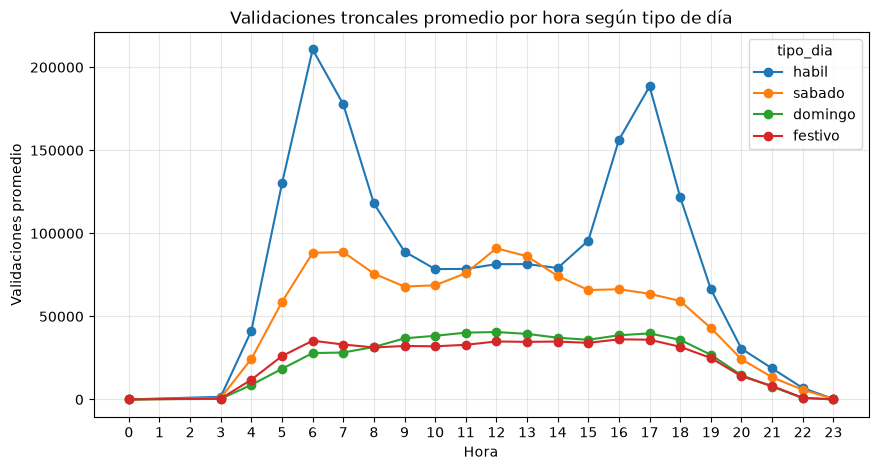

In [14]:
# Total por fecha y hora, luego promedio entre los días de cada tipo
sist = demanda.groupby(["fecha", "tipo_dia", "hora"], as_index=False)["validaciones"].sum()
curva = sist.groupby(["tipo_dia", "hora"])["validaciones"].mean().unstack(0)

curva[["habil", "sabado", "domingo", "festivo"]].plot(figsize=(10, 5), marker="o")
plt.title("Validaciones troncales promedio por hora según tipo de día")
plt.xlabel("Hora"); plt.ylabel("Validaciones promedio"); plt.xticks(range(0, 24))
plt.grid(alpha=.3); plt.show()

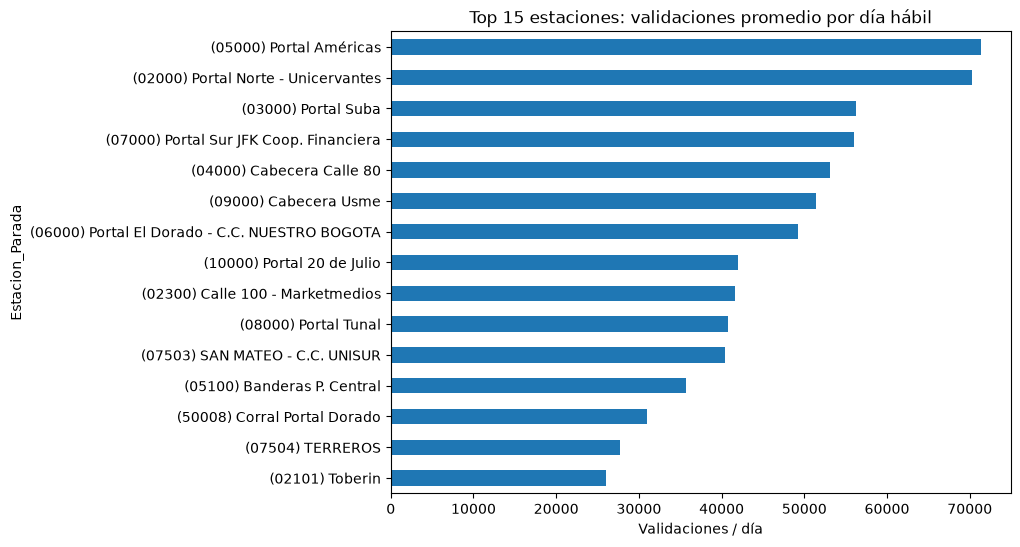

In [15]:
habil = demanda[demanda["tipo_dia"] == "habil"]
dias_habiles = habil["fecha"].nunique()

top = (habil.groupby("Estacion_Parada")["validaciones"].sum() / dias_habiles) \
        .sort_values(ascending=False).head(15)

top.sort_values().plot.barh(figsize=(8, 6))
plt.title("Top 15 estaciones: validaciones promedio por día hábil")
plt.xlabel("Validaciones / día"); plt.show()

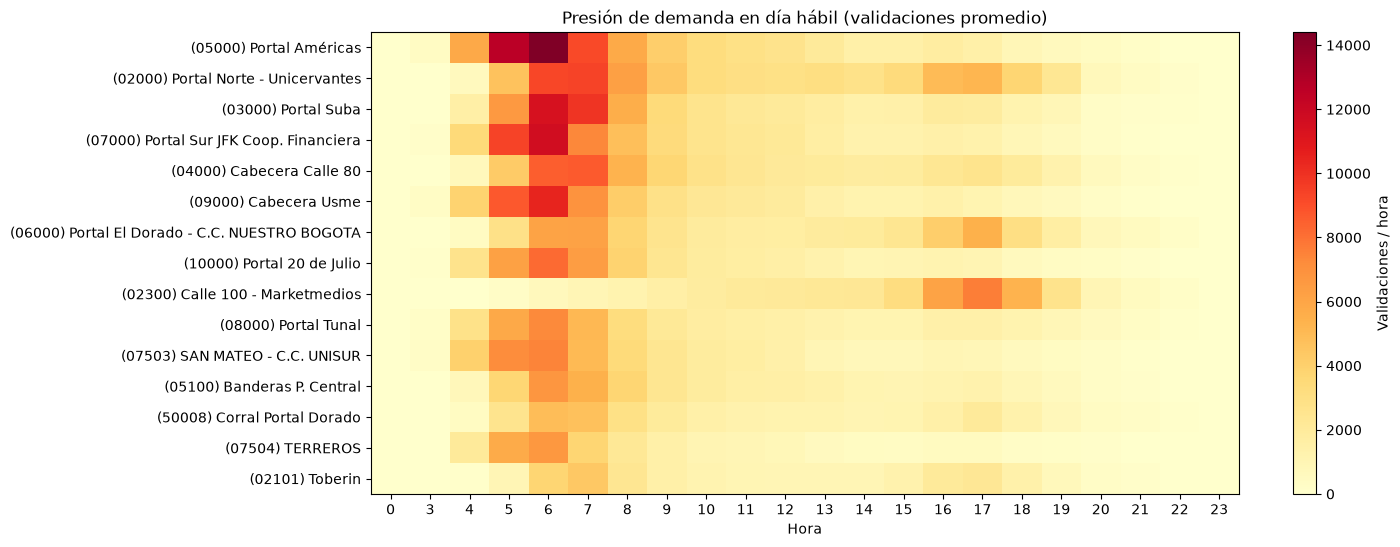

In [16]:
mat = (habil.groupby(["Estacion_Parada", "hora"])["validaciones"].sum() / dias_habiles) \
        .unstack(fill_value=0)
mat = mat.loc[top.index]          # mismas 15 estaciones del top

fig, ax = plt.subplots(figsize=(14, 6))
im = ax.imshow(mat.values, aspect="auto", cmap="YlOrRd")
ax.set_xticks(range(mat.shape[1])); ax.set_xticklabels(mat.columns)
ax.set_yticks(range(mat.shape[0])); ax.set_yticklabels(mat.index)
ax.set_xlabel("Hora"); ax.set_title("Presión de demanda en día hábil (validaciones promedio)")
fig.colorbar(im, ax=ax, label="Validaciones / hora"); plt.show()

In [17]:
perf = habil[habil["Estacion_Parada"].isin(top.index)] \
         .pivot_table(index="Estacion_Parada", columns="Nombre_Perfil",
                      values="validaciones", aggfunc="sum", fill_value=0)
pct = perf.div(perf.sum(axis=1), axis=0) * 100
pct[["(002) Adulto Mayor", "(001) Anonymous"]].round(1).sort_values("(002) Adulto Mayor")

Nombre_Perfil,(002) Adulto Mayor,(001) Anonymous
Estacion_Parada,,
(07504) TERREROS,5.1,38.6
(05000) Portal Américas,6.0,30.2
(07503) SAN MATEO - C.C. UNISUR,6.2,43.0
(08000) Portal Tunal,7.1,23.3
(09000) Cabecera Usme,7.1,21.6
(07000) Portal Sur JFK Coop. Financiera,7.5,23.9
(06000) Portal El Dorado - C.C. NUESTRO BOGOTA,7.6,18.6
(02000) Portal Norte - Unicervantes,7.6,38.5
(10000) Portal 20 de Julio,8.2,24.4


## Hallazgos preliminares del EDA

**1. La demanda depende fuertemente del tipo de día**

| Tipo de día | Días en la muestra | Validaciones promedio por día | % frente a día hábil |
|---|---|---|---|
| Hábil | 14 | ≈1,85 millones | 100 % |
| Sábado | 3 | ≈1,14 millones | 62 % |
| Domingo | 3 | ≈0,55 millones | 30 % |
| Festivo (7-ago) | 1 | ≈0,53 millones | 28 % |

El festivo se comporta prácticamente como un domingo, así que se analiza aparte y no entra en los promedios de día hábil.

**2. El día hábil tiene dos picos muy marcados** (curva horaria del sistema)
- **Pico AM: 5–7 a. m.**, con el máximo a las 6 a. m. (≈210.000 validaciones por hora en todo el sistema).
- **Pico PM: 4–6 p. m.**, con el máximo a las 5 p. m. (≈190.000 validaciones por hora).
- Entre picos la demanda baja a ≈80.000 por hora. Sábado, domingo y festivo no tienen picos marcados: la demanda es más plana y concentrada al mediodía.
- **Implicación para turnos:** el refuerzo de personal en día hábil se concentra en dos bloques cortos (≈3 horas cada uno), no en jornada continua.

**3. La presión se concentra en portales y cabeceras** (top 15 de día hábil)
- Las estaciones con más validaciones son **Portal Américas (≈71.000/día)** y **Portal Norte (≈70.000/día)**, seguidas por Portal Suba, Portal Sur, Cabecera Calle 80, Cabecera Usme y Portal El Dorado (≈49.000–56.000/día).
- El mapa de calor muestra que en la mayoría de portales la presión ocurre en el **pico AM (5–7 a. m.)**. Portal Américas alcanza ≈14.000 validaciones en la hora de las 6 a. m.

**4. Ya se ven perfiles de demanda distintos** (insumo para el clustering)
- **Perfil "residencial / origen"**: Portal Américas, Portal Sur, Cabecera Usme, Portal Suba y Portal Tunal concentran su demanda en la mañana. La gente sale de casa hacia el trabajo.
- **Perfil "destino laboral"**: Calle 100 tiene su pico en la tarde (4–6 p. m.), cuando la gente regresa a casa.
- **Perfil mixto**: Portal Norte y Portal El Dorado tienen pico AM y un segundo pico PM importante.
- **Implicación:** los turnos de apoyo no pueden ser iguales para todas las estaciones. Esta diferencia justifica construir los perfiles con clustering sobre la curva horaria.

**5. Perfil de usuarios en las estaciones de mayor demanda**
- El porcentaje de **adultos mayores** va de 5,1 % (Terreros) a 10,4 % (Cabecera Calle 80). Cabecera Calle 80, Banderas, Portal Suba, Calle 100 y Toberín están por encima del promedio del sistema (8,2 %).
- El uso de **tarjeta anónima** es más alto en San Mateo (43 %), Terreros (39 %) y Portal Norte (39 %), frente al 30 % del sistema.

**6. Pendiente de datos: estaciones sin cruce geográfico**
- 18 códigos de estación de las validaciones no están en la tabla oficial de 149 estaciones. Suman ≈2,7 millones de validaciones (**8,6 %** del total).
- Son principalmente **estaciones temporales** (Temporal Flores, Marly, Calle 57, Avenida 39, Av. Jiménez, Calle 22), **Corral Portal Dorado**, **ampliaciones o estaciones nuevas** (Ampliación San Mateo, Los Laureles, Islandia, Tibanica, Danubio, La Granja) y puntos con pocos registros.
- **Siguiente paso:** asignarles coordenadas manualmente o agruparlas con la estación oficial más cercana, para no perderlas en el análisis espacial (`demanda_zona_700m`).
- Las estaciones **"Corral"** (código 500xx) no están definidas en el diccionario de datos. Corral Portal Dorado (≈31.000 validaciones por día hábil) parece ser un punto de abordaje adicional del portal. Las que tienen una sola validación se excluyen como ruido. Ver el detalle en la sección *Estaciones sin cruce con la tabla oficial*.

**Próximos pasos**
1. Calcular las variables del Nivel 1 por estación (curva horaria normalizada, razón AM/PM, razón fin de semana/hábil, índice de concentración del pico) y aplicar clustering para obtener `perfil_demanda`.
2. Construir el `indice_prioridad` del Nivel 2 (estación × día de la semana × hora) para definir dónde y cuándo reforzar.